BUILD FINAL ADJUSTED STATION TABLE
Input CSV:
/home/users/jianxing/New_final/GAM_values/ACI/station_selection/selected_stations_and_screened_recommended_points_top4_newmonths_noseed_observation_evidence_v4_no_c2_recommended_cluster3_7points.csv

Updated full CSV:
/home/users/jianxing/New_final/GAM_values/ACI/station_selection/final_fig7_newmonths_noseed_observation_evidence_v4.csv

Compact table CSV:
/home/users/jianxing/New_final/GAM_values/ACI/station_selection/final_fig7_newmonths_noseed_observation_evidence_v4_table.csv

Counts by region and point type:
region_label        point_type  count
          R1 recommended_point      5
          R2  selected_station     10
          R3 recommended_point      7
          R3  selected_station      1

FINAL ACTUAL STATIONS AND RECOMMENDED POINTS
region cluster        point_type  city_name  latitude  longitude             coordinate_type  grid_latitude  grid_longitude           network grade feasibility_rank             province_region        

/tmp/ipykernel_12506/629127099.py:745: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['R1' 'R1' 'R1' 'R1' 'R1' 'R2' 'R2' 'R2' 'R2' 'R2' 'R2' 'R2' 'R2' 'R2'
 'R2' 'R3' 'R3' 'R3' 'R3' 'R3' 'R3' 'R3' 'R3']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  final_df.loc[
/tmp/ipykernel_12506/629127099.py:1075: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'actual_station_coordinate' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  final_df.loc[


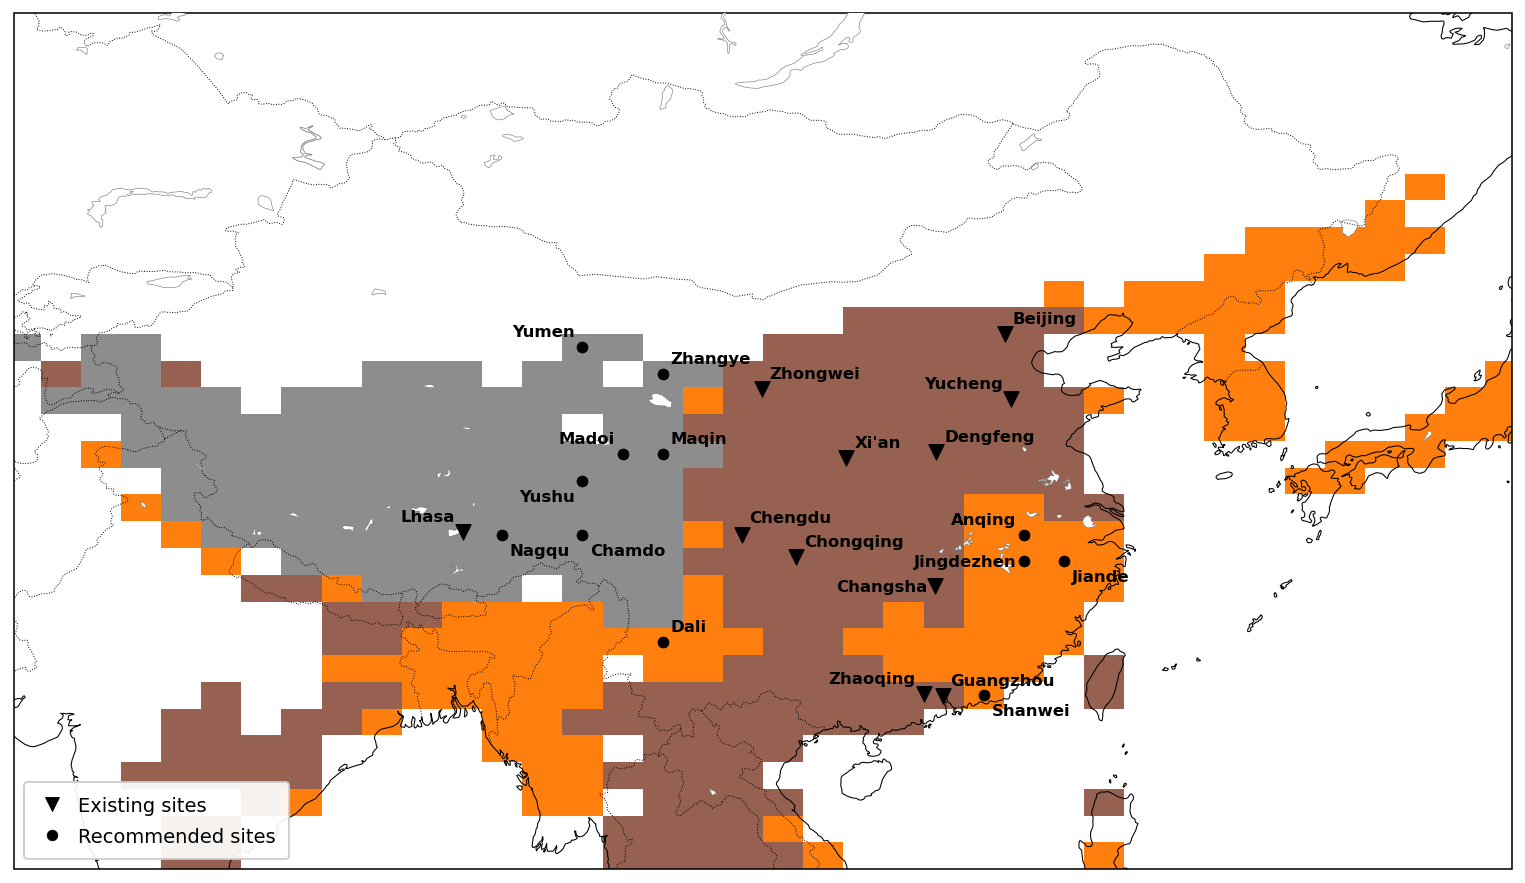


DONE


In [6]:
# ============================================================
# Final selected stations and recommended points map
#
# Adjustments for this version:
#   1. Use the final new-month / no-seed / observation-evidence v4 CSV.
#   2. Remove all recommended points from Cluster 2 / c5 / R2.
#   3. Keep existing stations in Cluster 2 / c5 / R2.
#   4. Do NOT add Shenyang/CYC manually.
#   5. Use the single final city_name in the v4 CSV for map labels.
#   6. Existing stations use actual station coordinates.
#   7. Recommended sites use the original scientific grid coordinates.
#   8. Do NOT save figure; show figure directly in notebook.
#   9. Legend labels:
#        Existing sites
#        Recommended sites
#  10. Label adjustment:
#        Guangzhou -> upper right
#        Jingdezhen -> lower left
# ============================================================

# ==== 导入库 ====
import os

import numpy as np
import pandas as pd
import xarray as xr
import iris

import matplotlib
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm
)

from matplotlib.lines import Line2D


# ============================================================
# ==== CONFIGURATION ====
# ============================================================

cluster_path = (
    "/home/users/jianxing/"
    "ERFaci_optimal_constraint_clusters.nc"
)

land_path = (
    "/home/users/jianxing/"
    "Step1_data/For_Jianxing/N96_land.pp"
)

out_dir = (
    "/home/users/jianxing/"
    "New_final/GAM_values/ACI/station_selection"
)

os.makedirs(
    out_dir,
    exist_ok=True
)

figure_dir = os.path.join(
    out_dir,
    "figures_fig7_newmonths_noseed_observation_evidence_v4"
)

os.makedirs(
    figure_dir,
    exist_ok=True
)

input_csv = os.path.join(
    out_dir,
    "selected_stations_and_screened_recommended_points_top4_newmonths_noseed_observation_evidence_v4_no_c2_recommended_cluster3_7points.csv"
)

output_csv = os.path.join(
    out_dir,
    "final_fig7_newmonths_noseed_observation_evidence_v4.csv"
)

output_table_csv = os.path.join(
    out_dir,
    "final_fig7_newmonths_noseed_observation_evidence_v4_table.csv"
)

save_figure = False

figure_output_file = os.path.join(
    figure_dir,
    "final_fig7_newmonths_noseed_observation_evidence_v4.png"
)


# ============================================================
# ==== MAP SETTINGS ====
# ============================================================

lat_min = 15
lat_max = 55

lon_min = 70
lon_max = 140

china_extent = [
    lon_min,
    lon_max,
    lat_min,
    lat_max
]

cluster_ids = [
    1.0,
    5.0,
    7.0
]

cluster_color_map = {
    "c1": "#ff7f0e",
    "c5": "#966150",
    "c7": "#8d8d8d"
}

cluster_cmap = ListedColormap([
    cluster_color_map["c1"],
    cluster_color_map["c5"],
    cluster_color_map["c7"]
])

cluster_bounds = [
    0.5,
    3.0,
    6.0,
    7.5
]

cluster_norm = BoundaryNorm(
    cluster_bounds,
    cluster_cmap.N
)

cluster_order = {
    "c1": 1,
    "c5": 2,
    "c7": 3
}

point_type_order = {
    "selected_station": 1,
    "recommended_point": 2
}

cluster_to_region_label = {
    "c1": "R1",
    "c5": "R2",
    "c7": "R3"
}

cluster_to_cluster_label = {
    "c1": "Cluster 1",
    "c5": "Cluster 2",
    "c7": "Cluster 3"
}


# ============================================================
# ==== POINT STYLE SETTINGS ====
# ============================================================

selected_station_marker = "v"
selected_station_size = 64
selected_station_color = "black"

recommended_point_marker = "o"
recommended_point_size = 32
recommended_point_color = "black"

show_city_labels = True

city_label_fontsize = 8.5
city_label_fontweight = "bold"

default_selected_station_label_offset = (
    4,
    4
)

default_recommended_point_label_offset = (
    4,
    -4
)

city_label_layout = {

    # =========================
    # Cluster 1 recommended sites
    # =========================

    # MODIFIED:
    # Jingdezhen -> lower left
    "jingdezhen": {
        "offset": (-4, -4),
        "ha": "right",
        "va": "bottom"
    },

    "jiande": {
        "offset": (4, -4),
        "ha": "left",
        "va": "top"
    },

    "anqing": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    },

    "dali": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "shanwei": {
        "offset": (4, -4),
        "ha": "left",
        "va": "top"
    },

    # =========================
    # Cluster 2 existing sites
    # =========================

    "zhaoqing": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    },

    "chongqing": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "chengdu": {
        "offset": (4, 5),
        "ha": "left",
        "va": "bottom"
    },

    "dengfeng": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "zhongwei": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "yucheng": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    },

    "changsha": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "top"
    },

    "xi'an": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    # MODIFIED:
    # Guangzhou -> upper right
    "guangzhou": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "beijing": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    # =========================
    # Cluster 3 existing + recommended sites
    # =========================

    "lhasa": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    },

    "nagqu": {
        "offset": (4, -4),
        "ha": "left",
        "va": "top"
    },

    "madoi": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    },

    "yushu": {
        "offset": (-4, -4),
        "ha": "right",
        "va": "top"
    },

    "maqin": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "chamdo": {
        "offset": (4, -4),
        "ha": "left",
        "va": "top"
    },

    "zhangye": {
        "offset": (4, 4),
        "ha": "left",
        "va": "bottom"
    },

    "yumen": {
        "offset": (-4, 4),
        "ha": "right",
        "va": "bottom"
    }
}

figure_size = (
    11,
    7.5
)

figure_dpi = 140


# ============================================================
# ==== READ CLUSTER AND LAND MASK ====
# ============================================================

def read_cluster_and_land_like_original():

    if not os.path.exists(
        cluster_path
    ):
        raise FileNotFoundError(
            f"Cluster file not found: {cluster_path}"
        )

    cluster_ds = xr.open_dataset(
        cluster_path
    )

    cluster = cluster_ds[
        "Cluster"
    ].values

    lat_cl = cluster_ds[
        "latitude"
    ].values

    lon_cl = cluster_ds[
        "longitude"
    ].values

    lon_cl_plot = np.where(
        lon_cl > 180,
        lon_cl - 360,
        lon_cl
    )

    lon_order = np.argsort(
        lon_cl_plot
    )

    lon_cl_plot = lon_cl_plot[
        lon_order
    ]

    cluster = cluster[
        :,
        lon_order
    ]

    if lat_cl[0] > lat_cl[-1]:

        lat_cl = lat_cl[
            ::-1
        ]

        cluster = cluster[
            ::-1,
            :
        ]

    lat_mask = (
        (lat_cl >= lat_min)
        &
        (lat_cl <= lat_max)
    )

    lon_mask = (
        (lon_cl_plot >= lon_min)
        &
        (lon_cl_plot <= lon_max)
    )

    lat_idx = np.where(
        lat_mask
    )[0]

    lon_idx = np.where(
        lon_mask
    )[0]

    cluster_cn = cluster[
        np.ix_(
            lat_idx,
            lon_idx
        )
    ]

    lat_cn = lat_cl[
        lat_idx
    ]

    lon_cn = lon_cl_plot[
        lon_idx
    ]

    if not os.path.exists(
        land_path
    ):
        raise FileNotFoundError(
            f"Land-mask file not found: {land_path}"
        )

    land_cube = iris.load_cube(
        land_path
    )

    land_mask_2d = (
        land_cube.data
        == 1
    )

    try:

        lat_land = land_cube.coord(
            "latitude"
        ).points

        lon_land = land_cube.coord(
            "longitude"
        ).points

    except Exception:

        lat_land = land_cube.coord(
            "grid_latitude"
        ).points

        lon_land = land_cube.coord(
            "grid_longitude"
        ).points

    lon_land_plot = np.where(
        lon_land > 180,
        lon_land - 360,
        lon_land
    )

    lon_land_order = np.argsort(
        lon_land_plot
    )

    lon_land_plot = lon_land_plot[
        lon_land_order
    ]

    land_mask_2d = land_mask_2d[
        :,
        lon_land_order
    ]

    if lat_land[0] > lat_land[-1]:

        lat_land = lat_land[
            ::-1
        ]

        land_mask_2d = land_mask_2d[
            ::-1,
            :
        ]

    land_da = xr.DataArray(
        land_mask_2d.astype(float),

        coords={
            "latitude": lat_land,
            "longitude": lon_land_plot
        },

        dims=[
            "latitude",
            "longitude"
        ]
    )

    land_on_cluster = land_da.interp(
        latitude=lat_cn,
        longitude=lon_cn,
        method="nearest"
    )

    land_cn = (
        land_on_cluster.values
        == 1
    )

    cluster_target_mask = np.isin(
        cluster_cn,
        cluster_ids
    )

    cluster_cn_land = np.where(
        land_cn
        &
        cluster_target_mask,

        cluster_cn,
        np.nan
    )

    return {
        "cluster_ds": cluster_ds,
        "land_cube": land_cube,
        "cluster_cn": cluster_cn,
        "cluster_cn_land": cluster_cn_land,
        "lat_cn": lat_cn,
        "lon_cn": lon_cn,
        "land_cn": land_cn
    }


# ============================================================
# ==== ADD MISSING COLUMNS ====
# ============================================================

def ensure_columns(
    dataframe,
    required_columns
):

    dataframe = dataframe.copy()

    for column_name in required_columns:

        if column_name not in dataframe.columns:

            dataframe[
                column_name
            ] = np.nan

    return dataframe


# ============================================================
# ==== APPLY FINAL ADJUSTMENTS ====
# ============================================================

def build_final_adjusted_dataframe(
    csv_file
):

    if not os.path.exists(
        csv_file
    ):
        raise FileNotFoundError(
            f"Input CSV not found: {csv_file}"
        )

    final_df = pd.read_csv(
        csv_file
    )

    required_columns = [
        "point_type",
        "cluster",
        "cluster_label",
        "region_label",

        "grid_region",
        "grid_lat",
        "grid_lon",

        "is_existing_station",

        "station_names",
        "station_codes",
        "networks",
        "grades",

        "station_lats",
        "station_lons",
        "station_lat_lon_records",

        "station_plot_lat",
        "station_plot_lon",

        "n_station_records",

        "selected_months_considered",
        "selected_month_hit_count",

        "hit_months",
        "high_similarity_months",

        "mean_selected_month_ccc",
        "max_selected_month_ccc",

        "ccc_by_selected_month",
        "important_parameters_by_month",

        "selection_reason",

        "screening_decision",
        "feasibility_rank",
        "nearest_city_or_base",
        "province_or_region",
        "country_screen",
        "feasibility_reason",

        "screening_status",
        "recommendation_rank_within_cluster",

        "country_check",
        "province_region",

        "nearby_city_or_town",
        "distance_to_nearby_place_km",

        "nearest_major_city",
        "distance_to_major_city_km",

        "field_feasibility_grade",

        "recommended_station_setting",
        "field_feasibility_reason",
        "main_constraints",
        "recommended_next_step",

        "screening_method",
        "location_data_source",
        "infrastructure_source",

        "city_name",
        "city_name_pinyin",

        "final_priority",
        "observation_evidence_strength",
        "observation_evidence_type",
        "observation_implementation_evidence",
        "final_selection_reason",
        "observation_evidence_source",

        "point_latitude",
        "point_longitude",
        "point_coordinate_type",

        "reference_city_latitude",
        "reference_city_longitude",

        "distance_point_to_reference_city_km",
        "city_name_update_source"
    ]

    final_df = ensure_columns(
        final_df,
        required_columns
    )

    final_df[
        "point_type"
    ] = (
        final_df[
            "point_type"
        ]
        .astype(str)
        .str.strip()
    )

    final_df[
        "cluster"
    ] = (
        final_df[
            "cluster"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # ==========================================
    # FILL REGION AND CLUSTER LABELS
    # ==========================================

    missing_region_label = (
        final_df[
            "region_label"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_region_label,
        "region_label"
    ] = (
        final_df.loc[
            missing_region_label,
            "cluster"
        ]
        .map(
            cluster_to_region_label
        )
    )

    missing_cluster_label = (
        final_df[
            "cluster_label"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_cluster_label,
        "cluster_label"
    ] = (
        final_df.loc[
            missing_cluster_label,
            "cluster"
        ]
        .map(
            cluster_to_cluster_label
        )
    )

    # ==========================================
    # COMPATIBLE COLUMNS
    # ==========================================

    missing_country_check = (
        final_df[
            "country_check"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_country_check,
        "country_check"
    ] = final_df.loc[
        missing_country_check,
        "country_screen"
    ]

    missing_province_region = (
        final_df[
            "province_region"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_province_region,
        "province_region"
    ] = final_df.loc[
        missing_province_region,
        "province_or_region"
    ]

    missing_feasibility_grade = (
        final_df[
            "field_feasibility_grade"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_feasibility_grade,
        "field_feasibility_grade"
    ] = final_df.loc[
        missing_feasibility_grade,
        "feasibility_rank"
    ]

    missing_feasibility_reason = (
        final_df[
            "field_feasibility_reason"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_feasibility_reason,
        "field_feasibility_reason"
    ] = final_df.loc[
        missing_feasibility_reason,
        "feasibility_reason"
    ]

    missing_city_name = (
        final_df[
            "city_name"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_city_name,
        "city_name"
    ] = final_df.loc[
        missing_city_name,
        "city_name_pinyin"
    ]

    missing_city_name = (
        final_df[
            "city_name"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_city_name,
        "city_name"
    ] = final_df.loc[
        missing_city_name,
        "nearest_city_or_base"
    ]

    # ==========================================
    # REMOVE CLUSTER 2 RECOMMENDED POINTS
    # ==========================================

    final_df = final_df[
        ~(
            (
                final_df[
                    "point_type"
                ]
                ==
                "recommended_point"
            )
            &
            (
                final_df[
                    "cluster"
                ]
                ==
                "c5"
            )
        )
    ].copy()

    # ==========================================
    # DO NOT ADD SHENYANG
    # ==========================================

    # Strictly use points already present in the v4 CSV.

    # ==========================================
    # DETERMINE PLOTTING COORDINATES
    # ==========================================

    final_df[
        "plot_lat"
    ] = pd.to_numeric(
        final_df[
            "point_latitude"
        ],
        errors="coerce"
    )

    final_df[
        "plot_lon"
    ] = pd.to_numeric(
        final_df[
            "point_longitude"
        ],
        errors="coerce"
    )

    selected_station_mask = (
        final_df[
            "point_type"
        ]
        ==
        "selected_station"
    )

    recommended_point_mask = (
        final_df[
            "point_type"
        ]
        ==
        "recommended_point"
    )

    station_lat_fallback = pd.to_numeric(
        final_df[
            "station_plot_lat"
        ],
        errors="coerce"
    )

    station_lon_fallback = pd.to_numeric(
        final_df[
            "station_plot_lon"
        ],
        errors="coerce"
    )

    grid_lat_fallback = pd.to_numeric(
        final_df[
            "grid_lat"
        ],
        errors="coerce"
    )

    grid_lon_fallback = pd.to_numeric(
        final_df[
            "grid_lon"
        ],
        errors="coerce"
    )

    missing_station_lat = (
        selected_station_mask
        &
        ~np.isfinite(
            final_df[
                "plot_lat"
            ]
        )
    )

    missing_station_lon = (
        selected_station_mask
        &
        ~np.isfinite(
            final_df[
                "plot_lon"
            ]
        )
    )

    missing_recommended_lat = (
        recommended_point_mask
        &
        ~np.isfinite(
            final_df[
                "plot_lat"
            ]
        )
    )

    missing_recommended_lon = (
        recommended_point_mask
        &
        ~np.isfinite(
            final_df[
                "plot_lon"
            ]
        )
    )

    final_df.loc[
        missing_station_lat,
        "plot_lat"
    ] = station_lat_fallback[
        missing_station_lat
    ]

    final_df.loc[
        missing_station_lon,
        "plot_lon"
    ] = station_lon_fallback[
        missing_station_lon
    ]

    final_df.loc[
        missing_recommended_lat,
        "plot_lat"
    ] = grid_lat_fallback[
        missing_recommended_lat
    ]

    final_df.loc[
        missing_recommended_lon,
        "plot_lon"
    ] = grid_lon_fallback[
        missing_recommended_lon
    ]

    missing_point_coordinate_type = (
        final_df[
            "point_coordinate_type"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
        ==
        ""
    )

    final_df.loc[
        missing_point_coordinate_type
        &
        selected_station_mask,
        "point_coordinate_type"
    ] = "actual_station_coordinate"

    final_df.loc[
        missing_point_coordinate_type
        &
        recommended_point_mask,
        "point_coordinate_type"
    ] = "recommended_grid_coordinate"

    # ==========================================
    # CITY LABEL
    # ==========================================

    final_df[
        "city_label"
    ] = (
        final_df[
            "city_name"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    missing_city_label = (
        final_df[
            "city_label"
        ]
        ==
        ""
    )

    final_df.loc[
        missing_city_label,
        "city_label"
    ] = (
        final_df.loc[
            missing_city_label,
            "nearest_city_or_base"
        ]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    missing_city_label = (
        final_df[
            "city_label"
        ]
        ==
        ""
    )

    final_df.loc[
        missing_city_label,
        "city_label"
    ] = (
        final_df.loc[
            missing_city_label,
            "station_names"
        ]
        .fillna("")
        .astype(str)
        .str.split(";")
        .str[0]
        .str.split("/")
        .str[0]
        .str.strip()
    )

    # ==========================================
    # VALID DATA
    # ==========================================

    valid_mask = (
        final_df[
            "point_type"
        ].isin([
            "selected_station",
            "recommended_point"
        ])
        &
        final_df[
            "cluster"
        ].isin([
            "c1",
            "c5",
            "c7"
        ])
        &
        np.isfinite(
            final_df[
                "plot_lat"
            ]
        )
        &
        np.isfinite(
            final_df[
                "plot_lon"
            ]
        )
    )

    invalid_df = final_df[
        ~valid_mask
    ].copy()

    final_df = final_df[
        valid_mask
    ].copy()

    # ==========================================
    # SORT
    # ==========================================

    final_df[
        "_cluster_order"
    ] = (
        final_df[
            "cluster"
        ]
        .map(
            cluster_order
        )
        .fillna(99)
    )

    final_df[
        "_point_type_order"
    ] = (
        final_df[
            "point_type"
        ]
        .map(
            point_type_order
        )
        .fillna(99)
    )

    final_df = (
        final_df
        .sort_values([
            "_cluster_order",
            "_point_type_order",
            "city_label"
        ])
        .drop(columns=[
            "_cluster_order",
            "_point_type_order"
        ])
        .reset_index(drop=True)
    )

    return (
        final_df,
        invalid_df
    )


# ============================================================
# ==== SAVE UPDATED CSV AND TABLE ====
# ============================================================

def save_adjusted_outputs(
    final_df
):

    temporary_columns = [
        "plot_lat",
        "plot_lon",
        "city_label"
    ]

    full_output_df = final_df.drop(
        columns=[
            column_name
            for column_name in temporary_columns
            if column_name in final_df.columns
        ]
    )

    full_output_df.to_csv(
        output_csv,
        index=False,
        encoding="utf-8-sig"
    )

    compact_table_df = pd.DataFrame({
        "region":
            final_df[
                "region_label"
            ],

        "cluster":
            final_df[
                "cluster"
            ],

        "point_type":
            final_df[
                "point_type"
            ],

        "city_name":
            final_df[
                "city_label"
            ],

        "latitude":
            final_df[
                "plot_lat"
            ],

        "longitude":
            final_df[
                "plot_lon"
            ],

        "coordinate_type":
            final_df[
                "point_coordinate_type"
            ],

        "grid_latitude":
            pd.to_numeric(
                final_df[
                    "grid_lat"
                ],
                errors="coerce"
            ),

        "grid_longitude":
            pd.to_numeric(
                final_df[
                    "grid_lon"
                ],
                errors="coerce"
            ),

        "network":
            final_df[
                "networks"
            ],

        "grade":
            final_df[
                "grades"
            ],

        "feasibility_rank":
            final_df[
                "field_feasibility_grade"
            ],

        "province_region":
            final_df[
                "province_region"
            ],

        "feasibility_reason":
            final_df[
                "field_feasibility_reason"
            ]
    })

    compact_table_df.to_csv(
        output_table_csv,
        index=False,
        encoding="utf-8-sig"
    )

    return compact_table_df


# ============================================================
# ==== ADD CITY LABELS ====
# ============================================================

def normalize_city_label_for_layout(
    city_label
):

    normalized_label = (
        str(
            city_label
        )
        .strip()
        .lower()
        .replace(
            "’",
            "'"
        )
        .replace(
            " ",
            ""
        )
    )

    return normalized_label


def add_city_labels(
    ax,
    point_df,
    point_type
):

    if not show_city_labels:
        return

    map_coordinate_transform = (
        ccrs.PlateCarree()
        ._as_mpl_transform(
            ax
        )
    )

    for _, row in point_df.iterrows():

        city_label = str(
            row[
                "city_label"
            ]
        ).strip()

        if city_label == "":
            continue

        point_lon = float(
            row[
                "plot_lon"
            ]
        )

        point_lat = float(
            row[
                "plot_lat"
            ]
        )

        if point_type == "selected_station":

            default_offset = (
                default_selected_station_label_offset
            )

            default_vertical_alignment = "bottom"

        else:

            default_offset = (
                default_recommended_point_label_offset
            )

            default_vertical_alignment = "top"

        label_offset_x = default_offset[0]
        label_offset_y = default_offset[1]

        horizontal_alignment = "left"

        vertical_alignment = (
            default_vertical_alignment
        )

        layout_key = (
            normalize_city_label_for_layout(
                city_label
            )
        )

        layout_settings = (
            city_label_layout.get(
                layout_key,
                {}
            )
        )

        if "offset" in layout_settings:

            label_offset_x = (
                layout_settings[
                    "offset"
                ][0]
            )

            label_offset_y = (
                layout_settings[
                    "offset"
                ][1]
            )

        horizontal_alignment = (
            layout_settings.get(
                "ha",
                horizontal_alignment
            )
        )

        vertical_alignment = (
            layout_settings.get(
                "va",
                vertical_alignment
            )
        )

        ax.annotate(
            city_label,

            xy=(
                point_lon,
                point_lat
            ),

            xycoords=map_coordinate_transform,

            xytext=(
                label_offset_x,
                label_offset_y
            ),

            textcoords="offset points",

            fontsize=city_label_fontsize,
            fontweight=city_label_fontweight,

            color="black",

            ha=horizontal_alignment,
            va=vertical_alignment,

            annotation_clip=False,
            zorder=12
        )


# ============================================================
# ==== PLOT FINAL MAP ====
# ============================================================

def plot_final_selection_map(
    cluster_cn_land,
    lat_cn,
    lon_cn,
    final_df
):

    selected_station_df = final_df[
        final_df[
            "point_type"
        ]
        ==
        "selected_station"
    ].copy()

    recommended_point_df = final_df[
        final_df[
            "point_type"
        ]
        ==
        "recommended_point"
    ].copy()

    fig = plt.figure(
        figsize=figure_size,
        dpi=figure_dpi
    )

    ax = plt.axes(
        projection=ccrs.PlateCarree()
    )

    # ==========================================
    # CLUSTER BACKGROUND
    # ==========================================

    ax.pcolormesh(
        lon_cn,
        lat_cn,
        cluster_cn_land,

        cmap=cluster_cmap,
        norm=cluster_norm,

        shading="auto",

        transform=ccrs.PlateCarree(),

        zorder=1
    )

    # ==========================================
    # GEOGRAPHICAL FEATURES
    # ==========================================

    ax.add_feature(
        cfeature.COASTLINE,
        linewidth=0.55,
        edgecolor="black",
        zorder=5
    )

    ax.add_feature(
        cfeature.BORDERS,
        linestyle=":",
        linewidth=0.50,
        edgecolor="black",
        zorder=5
    )

    ax.add_feature(
        cfeature.LAKES,
        facecolor="white",
        edgecolor="0.45",
        linewidth=0.30,
        zorder=4
    )

    ax.set_extent(
        china_extent,
        crs=ccrs.PlateCarree()
    )

    # ==========================================
    # RECOMMENDED POINTS
    # ==========================================

    if not recommended_point_df.empty:

        ax.scatter(
            recommended_point_df[
                "plot_lon"
            ],

            recommended_point_df[
                "plot_lat"
            ],

            marker=recommended_point_marker,
            s=recommended_point_size,

            c=recommended_point_color,

            edgecolors="black",
            linewidths=0.35,

            transform=ccrs.PlateCarree(),

            zorder=8
        )

    # ==========================================
    # SELECTED EXISTING STATIONS
    # ==========================================

    if not selected_station_df.empty:

        ax.scatter(
            selected_station_df[
                "plot_lon"
            ],

            selected_station_df[
                "plot_lat"
            ],

            marker=selected_station_marker,
            s=selected_station_size,

            c=selected_station_color,

            edgecolors="black",
            linewidths=0.45,

            transform=ccrs.PlateCarree(),

            zorder=9
        )

    # ==========================================
    # CITY LABELS
    # ==========================================

    add_city_labels(
        ax=ax,
        point_df=recommended_point_df,
        point_type="recommended_point"
    )

    add_city_labels(
        ax=ax,
        point_df=selected_station_df,
        point_type="selected_station"
    )

    # ==========================================
    # LEGEND
    # ==========================================

    selected_station_handle = Line2D(
        [0],
        [0],

        marker=selected_station_marker,
        linestyle="none",

        markerfacecolor=selected_station_color,
        markeredgecolor="black",
        markeredgewidth=0.45,

        markersize=7.5,

        label="Existing sites"
    )

    recommended_point_handle = Line2D(
        [0],
        [0],

        marker=recommended_point_marker,
        linestyle="none",

        markerfacecolor=recommended_point_color,
        markeredgecolor="black",
        markeredgewidth=0.35,

        markersize=5.5,

        label="Recommended sites"
    )

    ax.legend(
        handles=[
            selected_station_handle,
            recommended_point_handle
        ],

        loc="lower left",

        frameon=True,
        framealpha=0.92,

        fontsize=10.0,

        handlelength=1.5,
        handletextpad=0.6,

        borderpad=0.7,
        labelspacing=0.6
    )

    plt.tight_layout()

    # ==========================================
    # NOTEBOOK VERSION
    # ==========================================

    plt.show()


# ============================================================
# ==== MAIN PROGRAM ====
# ============================================================

# ==========================================
# STEP 1: APPLY FINAL ADJUSTMENTS
# ==========================================

print("=" * 100)
print("BUILD FINAL ADJUSTED STATION TABLE")
print("=" * 100)

final_df, invalid_df = (
    build_final_adjusted_dataframe(
        input_csv
    )
)

compact_table_df = save_adjusted_outputs(
    final_df
)

print(
    "Input CSV:"
)

print(
    input_csv
)

print("")
print(
    "Updated full CSV:"
)

print(
    output_csv
)

print("")
print(
    "Compact table CSV:"
)

print(
    output_table_csv
)

print("")
print(
    "Counts by region and point type:"
)

print(
    final_df
    .groupby([
        "region_label",
        "point_type"
    ])
    .size()
    .reset_index(
        name="count"
    )
    .to_string(
        index=False
    )
)

if not invalid_df.empty:

    print("")
    print(
        "[WARNING] Invalid rows not used:"
    )

    invalid_columns = [
        column_name
        for column_name in [
            "point_type",
            "cluster",
            "city_name",
            "nearest_city_or_base",
            "grid_lat",
            "grid_lon",
            "station_plot_lat",
            "station_plot_lon"
        ]
        if column_name in invalid_df.columns
    ]

    print(
        invalid_df[
            invalid_columns
        ].to_string(
            index=False
        )
    )


# ==========================================
# STEP 2: DISPLAY FINAL TABLE
# ==========================================

print("")
print("=" * 100)
print("FINAL ACTUAL STATIONS AND RECOMMENDED POINTS")
print("=" * 100)

print(
    compact_table_df.to_string(
        index=False
    )
)


# ==========================================
# STEP 3: READ CLUSTER AND LAND MASK
# ==========================================

print("")
print("=" * 100)
print("READ CLUSTER AND LAND MASK")
print("=" * 100)

cluster_land = (
    read_cluster_and_land_like_original()
)

cluster_ds = cluster_land[
    "cluster_ds"
]

land_cube = cluster_land[
    "land_cube"
]

cluster_cn = cluster_land[
    "cluster_cn"
]

cluster_cn_land = cluster_land[
    "cluster_cn_land"
]

lat_cn = cluster_land[
    "lat_cn"
]

lon_cn = cluster_land[
    "lon_cn"
]

land_cn = cluster_land[
    "land_cn"
]

print(
    "cluster original shape:",
    cluster_ds[
        "Cluster"
    ].values.shape
)

print(
    "land original shape:",
    land_cube.data.shape
)

print(
    "cluster China shape:",
    cluster_cn.shape
)

print(
    "land China shape after interpolation:",
    land_cn.shape
)

print(
    "latitude range:",
    lat_cn.min(),
    lat_cn.max()
)

print(
    "longitude range:",
    lon_cn.min(),
    lon_cn.max()
)


# ==========================================
# STEP 4: DRAW FINAL MAP
# ==========================================

print("")
print("=" * 100)
print("PLOT FINAL SELECTED STATIONS AND RECOMMENDED POINTS")
print("=" * 100)

plot_final_selection_map(
    cluster_cn_land=
        cluster_cn_land,

    lat_cn=
        lat_cn,

    lon_cn=
        lon_cn,

    final_df=
        final_df
)

print("")
print("=" * 100)
print("DONE")
print("=" * 100)